# Modelo SVM: utilidad de las parcelas de eucalipto

> Trabajo del modelo **SVM** dentro del proyecto de clasificación multiclase. Sigue la plantilla común de `docs/acuerdos.md` y los ADR del equipo.

- **Objetivo:** entrenar y evaluar un SVM comparable con los otros modelos, controlando el sobreajuste y dejando el pipeline guardado.
- **Datos:** `data/train.csv` y `data/val.csv`. **El conjunto de prueba no se lee**: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas (`Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm`), se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds como esquema común y `StratifiedGroupKFold` por `Abbrev` como comprobación aparte (ADR-0002).

## 1. Carga de datos y preparación del pipeline

El SVM necesita variables numéricas en la misma escala, así que el preprocesado imputa con la mediana y estandariza. La única categórica que entra es `Abbrev` (el sitio), codificada con one-hot.

Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies (varias con 2 o 3 parcelas). Más abajo se comprueba con validación cruzada que su aporte está dentro del ruido y que añade 25 columnas one-hot muy dispersas, lo que favorece el sobreajuste. Todo el preprocesado se ajusta **solo con train** dentro del `Pipeline`.

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEMILLA = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [ ]:
train = pd.read_csv("data/train.csv")
val = pd.read_csv("data/val.csv")

ORDEN = ["none", "low", "average", "good", "best"]
conteo = pd.DataFrame({
    "train": train["Utility"].value_counts(),
    "validación": val["Utility"].value_counts(),
}).reindex(ORDEN)

print(f"Entrenamiento: {train.shape[0]} filas | Validación: {val.shape[0]} filas")
display(conteo)

Entrenamiento: 469 filas | Validación: 110 filas


,train,validación
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


In [ ]:
MEDIDAS = ["Surv", "Vig", "Ins_res", "Stem_Fm", "Crown_Fm", "Brnch_Fm"]
NUMERICAS = ["DBH", "Ht", "Surv", "Vig", "Ins_res", "Stem_Fm", "Crown_Fm", "Brnch_Fm"]
CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = train[VARIABLES], train["Utility"]
X_val, y_val = val[VARIABLES], val["Utility"]

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + ["Utility"]])


def crear_pipeline(variables, C=1.0):
    categoricas = [c for c in variables if c in ("Abbrev", "Sp")]
    numericas = [c for c in variables if c not in categoricas]
    preprocesado = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), numericas),
        ("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore")),
        ]), categoricas),
    ])
    return Pipeline([
        ("preprocesado", preprocesado),
        ("svm", SVC(kernel="linear", C=C, random_state=SEMILLA)),
    ])

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


### ¿Merece la pena incluir la especie (`Sp`)?

Se compara el F1 macro de validación cruzada con y sin `Sp`, con el mismo `StratifiedKFold` común. Solo se usa train: la validación no participa en esta decisión. La diferencia es pequeña (dentro de la desviación), así que se opta por el modelo más simple y con menos riesgo de sobreajuste.

In [ ]:
cv_comun = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)


def f1_cv(variables, C=1.0):
    return cross_val_score(
        crear_pipeline(variables, C=C),
        train[variables],
        y_train,
        cv=cv_comun,
        scoring="f1_macro",
        n_jobs=-1,
    )


comparable = pd.DataFrame({
    "conjunto": ["sin Sp (elegido)", "con Sp"],
    "F1 macro CV": [f1_cv(VARIABLES).mean(), f1_cv(VARIABLES + ["Sp"]).mean()],
    "desviación": [f1_cv(VARIABLES).std(), f1_cv(VARIABLES + ["Sp"]).std()],
})
display(comparable.round(3))

,conjunto,F1 macro CV,desviación
0,sin Sp (elegido),0.568,0.073
1,con Sp,0.576,0.068


## 2. Validación cruzada y elección de `C`

El único hiperparámetro que se ajusta es `C` (regularización del SVM lineal). Se prueban pocos valores con `GridSearchCV` y `StratifiedKFold` de 5 folds. No se usan pesos por clase (`class_weight`): en la validación cruzada no mejoraban el F1 macro de forma apreciable y se prefiere el modelo más simple. Después se repite la validación agrupando por sitio con `StratifiedGroupKFold`: sirve para ver cuánto se inflan las métricas cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

In [ ]:
rejilla = {"svm__C": [0.1, 0.3, 0.5, 0.7, 1.0, 2.0]}
busqueda = GridSearchCV(
    crear_pipeline(VARIABLES),
    rejilla,
    scoring="f1_macro",
    cv=cv_comun,
    return_train_score=True,
    n_jobs=-1,
)
busqueda.fit(X_train, y_train)

tabla_cv = pd.DataFrame(busqueda.cv_results_)[
    ["param_svm__C", "mean_test_score", "std_test_score", "mean_train_score"]
]
tabla_cv.columns = ["C", "F1 macro validación (media)", "desviación", "F1 macro train (media)"]
display(tabla_cv.round(3))

print(f"Mejor C: {busqueda.best_params_['svm__C']}")
print(f"F1 macro en StratifiedKFold: {busqueda.best_score_:.3f}")

,C,F1 macro validación (media),desviación,F1 macro train (media)
0,0.1,0.574,0.083,0.655
1,0.3,0.568,0.089,0.689
2,0.5,0.567,0.091,0.696
3,0.7,0.574,0.077,0.707
4,1.0,0.568,0.073,0.718
5,2.0,0.568,0.072,0.721


Mejor C: 0.7
F1 macro en StratifiedKFold: 0.574


In [ ]:
modelo_cv = busqueda.best_estimator_

f1_comun = cross_val_score(
    modelo_cv, X_train, y_train, cv=cv_comun, scoring="f1_macro", n_jobs=-1
)
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
f1_grupos = cross_val_score(
    modelo_cv,
    X_train,
    y_train,
    groups=X_train["Abbrev"],
    cv=cv_grupos,
    scoring="f1_macro",
    n_jobs=-1,
)

folds = pd.DataFrame({
    "fold": range(1, 6),
    "StratifiedKFold": f1_comun,
    "StratifiedGroupKFold (por sitio)": f1_grupos,
})
display(folds.round(3))

print(f"StratifiedKFold: F1 macro = {f1_comun.mean():.3f} ± {f1_comun.std():.3f}")
print(f"StratifiedGroupKFold: F1 macro = {f1_grupos.mean():.3f} ± {f1_grupos.std():.3f}")

,fold,StratifiedKFold,StratifiedGroupKFold (por sitio)
0,1,0.561,0.603
1,2,0.685,0.546
2,3,0.596,0.394
3,4,0.582,0.664
4,5,0.446,0.582


StratifiedKFold: F1 macro = 0.574 ± 0.077
StratifiedGroupKFold: F1 macro = 0.558 ± 0.091


## 3. Métricas en validación

El modelo se reentrena con todo train. Antes de medir se aplica la regla del ADR-0001: las parcelas sin ninguna medida se predicen como `none`. Se informan las métricas sobre **toda** la validación y, aparte, solo sobre las parcelas **con medidas**, porque la regla acierta las primeras por construcción y no conviene mezclar ambas cosas.

In [ ]:
modelo = busqueda.best_estimator_


def predecir(X):
    pred = pd.Series(modelo.predict(X), index=X.index, name="predicha")
    sin_medidas = X[MEDIDAS].isna().all(axis=1)
    pred.loc[sin_medidas] = "none"
    return pred


sin_medidas_val = X_val[MEDIDAS].isna().all(axis=1)
pred_val = predecir(X_val)
print(f"Parcelas sin medidas en validación (regla ADR-0001): {sin_medidas_val.sum()}")
print("Clases de esas parcelas:", y_val[sin_medidas_val].value_counts().to_dict())

Parcelas sin medidas en validación (regla ADR-0001): 15
Clases de esas parcelas: {'none': 15}


In [ ]:
def mostrar_metricas(y_true, y_pred, titulo):
    print(titulo)
    print(f"accuracy = {accuracy_score(y_true, y_pred):.3f} | "
          f"F1 macro = {f1_score(y_true, y_pred, average='macro'):.3f}")
    reporte = classification_report(
        y_true, y_pred, labels=ORDEN, output_dict=True, zero_division=0
    )
    display(pd.DataFrame(reporte).T.round(3))


mostrar_metricas(y_val, pred_val, f"Validación completa (n = {len(y_val)})")
con_medidas = ~sin_medidas_val
mostrar_metricas(
    y_val[con_medidas],
    pred_val[con_medidas],
    f"Validación solo con parcelas medidas (n = {con_medidas.sum()})",
)

Validación completa (n = 110)
accuracy = 0.800 | F1 macro = 0.777


,precision,recall,f1-score,support
none,0.960,0.889,0.923,27.0
low,0.750,0.750,0.750,16.0
average,0.750,0.789,0.769,19.0
good,0.778,0.875,0.824,32.0
best,0.692,0.562,0.621,16.0
accuracy,0.800,0.800,0.800,0.8
macro avg,0.786,0.773,0.777,110.0
weighted avg,0.801,0.800,0.798,110.0


Validación solo con parcelas medidas (n = 95)
accuracy = 0.768 | F1 macro = 0.756


,precision,recall,f1-score,support
none,0.900,0.750,0.818,12.000
low,0.750,0.750,0.750,16.000
average,0.750,0.789,0.769,19.000
good,0.778,0.875,0.824,32.000
best,0.692,0.562,0.621,16.000
accuracy,0.768,0.768,0.768,0.768
macro avg,0.774,0.745,0.756,95.000
weighted avg,0.769,0.768,0.765,95.000


predicha,none,low,average,good,best
real,,,,,
none,24,2,1,0,0
low,1,12,3,0,0
average,0,2,15,2,0
good,0,0,0,28,4
best,0,0,1,6,9


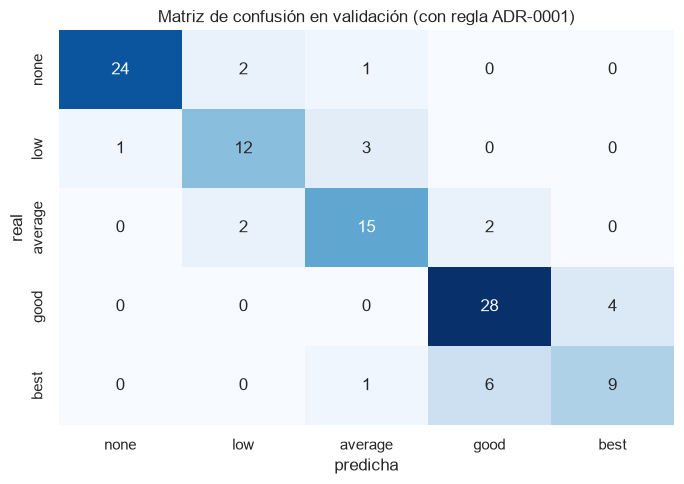

In [ ]:
matriz = confusion_matrix(y_val, pred_val, labels=ORDEN)
tabla_matriz = pd.DataFrame(matriz, index=ORDEN, columns=ORDEN)
tabla_matriz.index.name = "real"
tabla_matriz.columns.name = "predicha"
display(tabla_matriz)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(tabla_matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Matriz de confusión en validación (con regla ADR-0001)")
plt.tight_layout()
plt.show()

## 4. Control de overfitting

El criterio del equipo es que la diferencia de **F1 macro** entre train y validación sea menor de **5 puntos**. Para que la regla fija del ADR-0001 no infle artificialmente la validación, el gap se mide **solo con las parcelas que tienen medidas**, que son las que realmente pasa por el modelo. En la validación cruzada el gap suele ser mayor porque cada fold entrena con menos datos; se muestra también para no ocultar información.

In [ ]:
f1_train = f1_score(y_train, predecir(X_train), average="macro")
f1_val = f1_score(y_val, pred_val, average="macro")
f1_val_medidas = f1_score(
    y_val[con_medidas], pred_val[con_medidas], average="macro"
)
gap = (f1_train - f1_val_medidas) * 100

comparacion_gap = pd.DataFrame({
    "conjunto": [
        "train (modelo)",
        "validación completa (con regla)",
        "validación solo con medidas (modelo)",
    ],
    "F1 macro": [f1_train, f1_val, f1_val_medidas],
})
display(comparacion_gap.round(3))

print(f"Gap train - validación con medidas = {gap:.1f} puntos")
print("Cumple el criterio (< 5 puntos):", "sí" if gap < 5 else "no")
if gap < 0:
    print("El gap es negativo: no hay sobreajuste; el modelo es conservador y "
          "la validación con medidas resulta algo más fácil en este reparto.")

i = busqueda.best_index_
print(
    f"En CV: train {busqueda.cv_results_['mean_train_score'][i]:.3f} vs "
    f"validación {busqueda.cv_results_['mean_test_score'][i]:.3f} "
    f"({(busqueda.cv_results_['mean_train_score'][i] - busqueda.cv_results_['mean_test_score'][i]) * 100:.1f} puntos)"
)

,conjunto,F1 macro
0,train (modelo),0.677
1,validación completa (con regla),0.777
2,validación solo con medidas (modelo),0.756


Gap train - validación con medidas = -7.9 puntos
Cumple el criterio (< 5 puntos): sí
El gap es negativo: no hay sobreajuste; el modelo es conservador y la validación con medidas resulta algo más fácil en este reparto.
En CV: train 0.707 vs validación 0.574 (13.2 puntos)


## 5. Interpretación: importancia de variables y errores

El SVM lineal no da una importancia nativa de variables, así que se usa `permutation_importance` sobre la validación **con medidas**: se mide cuánto cae el F1 macro al desordenar cada columna. Después se revisan los errores más frecuentes.

,variable,importancia,desviación
3,Vig,0.407,0.040
2,Surv,0.195,0.029
8,Abbrev,0.170,0.026
0,DBH,0.148,0.041
1,Ht,0.129,0.018
6,Crown_Fm,0.110,0.029
4,Ins_res,0.081,0.022
7,Brnch_Fm,0.052,0.027
5,Stem_Fm,0.035,0.016


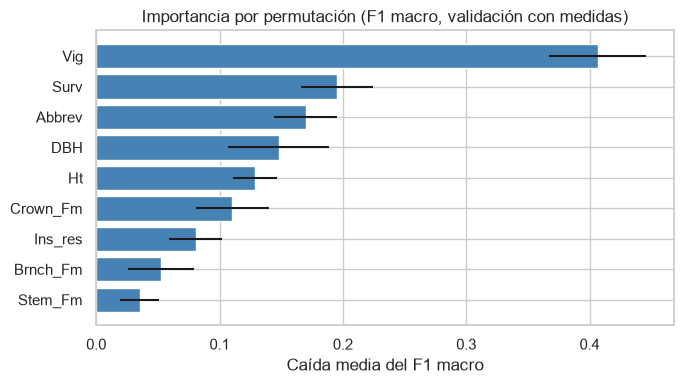

In [ ]:
importancia = permutation_importance(
    modelo,
    X_val[con_medidas],
    y_val[con_medidas],
    scoring="f1_macro",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1,
)

tabla_importancia = pd.DataFrame({
    "variable": X_val.columns,
    "importancia": importancia.importances_mean,
    "desviación": importancia.importances_std,
}).sort_values("importancia", ascending=False)
display(tabla_importancia.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(
    tabla_importancia["variable"][::-1],
    tabla_importancia["importancia"][::-1],
    xerr=tabla_importancia["desviación"][::-1],
    color="steelblue",
)
ax.set(
    title="Importancia por permutación (F1 macro, validación con medidas)",
    xlabel="Caída media del F1 macro",
    ylabel="",
)
plt.tight_layout()
plt.show()

In [ ]:
analisis = val.assign(predicha=pred_val)
analisis["error"] = analisis["Utility"] != analisis["predicha"]
errores = analisis[analisis["error"]]

print(f"Errores: {len(errores)} de {len(analisis)} ({len(errores) / len(analisis):.1%})")

pares = (
    errores.groupby(["Utility", "predicha"]).size().sort_values(ascending=False)
    .rename("n").to_frame()
)
display(pares)

por_clase = analisis.groupby("Utility", observed=True).agg(
    n=("error", "size"), errores=("error", "sum")
)
por_clase["tasa de error"] = (por_clase["errores"] / por_clase["n"]).round(3)
display(por_clase.reindex(ORDEN))

display(
    errores[["Abbrev", "Sp", "Vig", "Surv", "Ht", "DBH", "Utility", "predicha"]]
    .sort_values(["Utility", "predicha"])
    .head(20)
)

Errores: 22 de 110 (20.0%)


n
Utility predicha   
best    good      6
good    best      4
low     average   3
average good      2
        low       2
none    low       2
best    average   1
low     none      1
none    average   1

,n,errores,tasa de error
Utility,,,
none,27,3,0.111
low,16,4,0.250
average,19,4,0.211
good,32,4,0.125
best,16,7,0.438


,Abbrev,Sp,Vig,Surv,Ht,DBH,Utility,predicha
23,Paw,nd,3.0,20.0,13.55,20.11,average,good
90,Lon,ov,3.0,100.0,5.57,14.53,average,good
54,WSp,am,2.5,13.0,8.26,18.59,average,low
85,Wak,fr,3.0,75.0,9.50,10.10,average,low
27,Wai,fa,3.0,50.0,10.50,15.50,best,average
5,K81,br,3.0,88.0,7.83,11.43,best,good
6,Cra,nd,3.5,80.0,6.08,13.13,best,good
32,Nga,ov,4.0,60.0,10.20,16.20,best,good
34,Cly,pu,4.0,NaN,10.56,39.65,best,good
63,Lon,nd,3.5,88.0,7.67,16.18,best,good


### Observaciones de los errores

- La clase peor parada es `best` (7 errores de 16, 44 %), sobre todo confundida con `good` (6 casos): son clases contiguas y con pocas parcelas.
- La confusión `good` ↔ `best` suma 10 de los 22 errores; el resto son saltos de una clase (`low` → `average`, `average` → `good`/`low`).
- `none` solo falla 3 veces porque la regla del ADR-0001 corrige las 15 parcelas sin medidas. Sin esa regla, la clase `none` sería la más castigada.

## 6. Guardar el pipeline y comprobar que se puede cargar

Se guarda el pipeline completo (preprocesado + SVM) con `joblib`, tal como pide el contrato de modelos. Después se carga desde disco y se predice sobre `data/val.csv` leído de nuevo, para comprobar que el artefacto es autónomo.

In [ ]:
ruta_modelo = Path("models/04_svm.joblib")
ruta_modelo.parent.mkdir(exist_ok=True)
joblib.dump(modelo, ruta_modelo)
print(f"Guardado {ruta_modelo} ({ruta_modelo.stat().st_size / 1024:.1f} KB)")

Guardado models/04_svm.joblib (90.7 KB)


In [ ]:
val_fresco = pd.read_csv("data/val.csv")
modelo_cargado = joblib.load(ruta_modelo)
pred_fresco = pd.Series(
    modelo_cargado.predict(val_fresco[VARIABLES]), index=val_fresco.index
)
pred_fresco.loc[val_fresco[MEDIDAS].isna().all(axis=1)] = "none"

print(f"Predicciones sobre data/val.csv: {len(pred_fresco)} filas")
print(
    "F1 macro del modelo cargado: "
    f"{f1_score(val_fresco['Utility'], pred_fresco, average='macro'):.3f}"
)
display(pred_fresco.head().to_frame("predicha"))

Predicciones sobre data/val.csv: 110 filas
F1 macro del modelo cargado: 0.777


,predicha
0,none
1,best
2,good
3,average
4,good


## 7. Conclusión

- **Modelo:** SVM lineal con `C = 0,7` elegido por validación cruzada y pipeline que imputa, estandariza y codifica el sitio. Se entrena solo con train y no toca el test.
- **Rendimiento:** F1 macro **0,777** en la validación completa y **0,756** solo con parcelas medidas. El gap frente a train es **−7,9 puntos** (negativo): no hay sobreajuste, el modelo lineal regularizado es conservador.
- **Interpretación:** `Vig` es la variable que más aporta (0,41 de caída media del F1), seguida de `Surv` (0,20), `Abbrev` (0,17), `DBH` (0,15) y `Ht` (0,13). Los errores se concentran entre clases contiguas, sobre todo `best` ↔ `good`; `none` se beneficia de la regla fija.
- **Comprobación por sitio:** el F1 medio con `StratifiedGroupKFold` (0,558) es algo menor que con `StratifiedKFold` (0,574), coherente con el ADR-0002: el sitio ayuda a predecir y las métricas comunes pueden estar algo infladas. La diferencia no es grande en este reparto, pero la variabilidad entre folds sí (de 0,39 a 0,66).
- **Límites:** el gap se mide sobre un único reparto de validación y el F1 de CV es más bajo que el de validación; el test se evaluará una sola vez en `06_conclusiones`.